In [ ]:

import os
import json
import shutil
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from pathlib import Path
from nibabel.processing import resample_to_output

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from pathlib import Path
import os

print("Current working directory:")
print(Path.cwd())

Current working directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone\code


In [3]:
# Current directory is the "code" folder
CODE_DIR = Path.cwd()

# Project directories
DATA_DIR = CODE_DIR / "data"
OUTPUT_DIR = CODE_DIR / "processed_member1"

# Create output directory
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Verify paths
print("Current working directory:")
print(CODE_DIR)

print("\nDataset directory:")
print(DATA_DIR)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nDataset exists:", DATA_DIR.exists())

Current working directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone\code

Dataset directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data

Output directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\processed_member1

Dataset exists: True


In [4]:
# Find all task-fe fMRI files

fmri_files = sorted(
    DATA_DIR.glob("sub-*/func/*_task-fe_bold.nii.gz")
)

print("Number of fMRI files found:", len(fmri_files))

print("\nFiles:")
for file in fmri_files:
    print(file.relative_to(DATA_DIR))

Number of fMRI files found: 40

Files:
sub-01\func\sub-01_task-fe_bold.nii.gz
sub-02\func\sub-02_task-fe_bold.nii.gz
sub-03\func\sub-03_task-fe_bold.nii.gz
sub-04\func\sub-04_task-fe_bold.nii.gz
sub-05\func\sub-05_task-fe_bold.nii.gz
sub-06\func\sub-06_task-fe_bold.nii.gz
sub-07\func\sub-07_task-fe_bold.nii.gz
sub-08\func\sub-08_task-fe_bold.nii.gz
sub-09\func\sub-09_task-fe_bold.nii.gz
sub-10\func\sub-10_task-fe_bold.nii.gz
sub-11\func\sub-11_task-fe_bold.nii.gz
sub-12\func\sub-12_task-fe_bold.nii.gz
sub-13\func\sub-13_task-fe_bold.nii.gz
sub-14\func\sub-14_task-fe_bold.nii.gz
sub-15\func\sub-15_task-fe_bold.nii.gz
sub-16\func\sub-16_task-fe_bold.nii.gz
sub-17\func\sub-17_task-fe_bold.nii.gz
sub-18\func\sub-18_task-fe_bold.nii.gz
sub-19\func\sub-19_task-fe_bold.nii.gz
sub-20\func\sub-20_task-fe_bold.nii.gz
sub-21\func\sub-21_task-fe_bold.nii.gz
sub-22\func\sub-22_task-fe_bold.nii.gz
sub-23\func\sub-23_task-fe_bold.nii.gz
sub-24\func\sub-24_task-fe_bold.nii.gz
sub-25\func\sub-25_task-f

In [5]:
# Verify fMRI dataset properties

dataset_info = []

for file in fmri_files:
    img = nib.load(file)

    zooms = img.header.get_zooms()

    dataset_info.append({
        "subject": file.parent.parent.name,
        "shape": img.shape,
        "voxel_x": zooms[0],
        "voxel_y": zooms[1],
        "voxel_z": zooms[2],
        "TR": zooms[3] if len(zooms) > 3 else np.nan,
        "dtype": img.get_data_dtype(),
    })

dataset_info = pd.DataFrame(dataset_info)

display(dataset_info)

,subject,shape,voxel_x,voxel_y,voxel_z,TR,dtype
0,sub-01,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
1,sub-02,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
2,sub-03,"(128, 128, 36, 200)",1.789827,1.789827,4.0,3.000001,int16
3,sub-04,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
4,sub-05,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
5,sub-06,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
6,sub-07,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
7,sub-08,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
8,sub-09,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16
9,sub-10,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001,int16


In [6]:
# Check affine matrices and image orientations

orientation_info = []

for file in fmri_files:
    img = nib.load(file)

    orientation = nib.aff2axcodes(img.affine)

    orientation_info.append({
        "subject": file.parent.parent.name,
        "orientation": "".join(orientation),
        "affine": img.affine
    })

orientation_df = pd.DataFrame(
    [
        {
            "subject": item["subject"],
            "orientation": item["orientation"]
        }
        for item in orientation_info
    ]
)

display(orientation_df)

print("\nUnique orientations:")
print(orientation_df["orientation"].value_counts())

,subject,orientation
0,sub-01,LAS
1,sub-02,LAS
2,sub-03,LAS
3,sub-04,LAS
4,sub-05,LAS
5,sub-06,LAS
6,sub-07,LAS
7,sub-08,LAS
8,sub-09,LAS
9,sub-10,LAS



Unique orientations:
orientation
LAS    40
Name: count, dtype: int64


In [8]:
# Check intensity characteristics for all subjects

intensity_summary = []

for file in fmri_files:
    img = nib.load(file)
    data = img.get_fdata(dtype=np.float32)

    nonzero = data[data > 0]

    intensity_summary.append({
        "subject": file.parent.parent.name,
        "min": float(data.min()),
        "max": float(data.max()),
        "mean": float(data.mean()),
        "std": float(data.std()),
        "p1": float(np.percentile(nonzero, 1)),
        "p5": float(np.percentile(nonzero, 5)),
        "median": float(np.percentile(nonzero, 50)),
        "p95": float(np.percentile(nonzero, 95)),
        "p99": float(np.percentile(nonzero, 99)),
        "zero_percentage": float(
            100 * np.mean(data == 0)
        )
    })

intensity_summary = pd.DataFrame(intensity_summary)

display(intensity_summary)

KeyboardInterrupt: 

In [9]:
# Fast intensity analysis for preprocessing decision

sample_subjects = ["sub-01", "sub-10", "sub-20", "sub-30", "sub-40"]

sample_files = [
    file
    for file in fmri_files
    if file.parent.parent.name in sample_subjects
]

intensity_summary = []

for file in sample_files:

    subject = file.parent.parent.name
    print("Analyzing:", subject)

    img = nib.load(file)

    # Load only the first time point
    data = img.slicer[:, :, :, 0].get_fdata(dtype=np.float32)

    nonzero = data[data > 0]

    intensity_summary.append({
        "subject": subject,
        "min": float(data.min()),
        "max": float(data.max()),
        "mean": float(data.mean()),
        "std": float(data.std()),
        "p1": float(np.percentile(nonzero, 1)),
        "p5": float(np.percentile(nonzero, 5)),
        "median": float(np.percentile(nonzero, 50)),
        "p95": float(np.percentile(nonzero, 95)),
        "p99": float(np.percentile(nonzero, 99)),
        "zero_percentage": float(
            100 * np.mean(data == 0)
        )
    })

intensity_summary = pd.DataFrame(intensity_summary)

display(intensity_summary)

Analyzing: sub-01
Analyzing: sub-10
Analyzing: sub-20
Analyzing: sub-30
Analyzing: sub-40


,subject,min,max,mean,std,p1,p5,median,p95,p99,zero_percentage
0,sub-01,0.0,116229.726562,7080.851074,15387.927734,35.884449,35.884449,251.191147,47582.781250,57307.464844,9.587436
1,sub-10,0.0,132217.406250,7324.528809,15703.632812,32.303299,32.303299,387.639587,47518.152344,59405.765625,9.286160
2,sub-20,0.0,135177.062500,8532.127930,17438.617188,33.026402,33.026402,429.343231,50827.632812,65293.195312,9.014723
3,sub-30,0.0,113207.531250,8352.113281,16686.046875,41.544048,41.544048,456.984528,49395.875000,63479.304688,16.341485
4,sub-40,0.0,137159.296875,8734.241211,17118.000000,33.502514,33.502514,335.025146,49416.207031,61510.617188,5.554030


In [10]:
# ============================================
# Log Transformation - Sub-01
# ============================================

# Select sub-01
sub01_file = [
    file for file in fmri_files
    if file.parent.parent.name == "sub-01"
][0]

# Load NIfTI
sub01_img = nib.load(sub01_file)

# Load data as float32
sub01_data = sub01_img.get_fdata(dtype=np.float32)

print("Original shape:", sub01_data.shape)
print("Original dtype:", sub01_data.dtype)

# ------------------------------------------------
# Log transformation
# ------------------------------------------------

# Create output array
log_data = np.zeros_like(sub01_data, dtype=np.float32)

# Preserve background voxels (zero values)
nonzero_mask = sub01_data > 0

# Log transformation
log_data[nonzero_mask] = np.log1p(
    sub01_data[nonzero_mask]
)

print("\nLog transformation completed.")

print("\nOriginal intensity:")
print("Min :", sub01_data.min())
print("Max :", sub01_data.max())
print("Mean:", sub01_data.mean())
print("Std :", sub01_data.std())

print("\nLog-transformed intensity:")
print("Min :", log_data.min())
print("Max :", log_data.max())
print("Mean:", log_data.mean())
print("Std :", log_data.std())

Original shape: (128, 128, 36, 200)
Original dtype: float32

Log transformation completed.

Original intensity:
Min : 0.0
Max : 132305.97
Mean: 7060.444
Std : 15352.271

Log-transformed intensity:
Min : 0.0
Max : 11.79288
Mean: 5.72995
Std : 2.963848


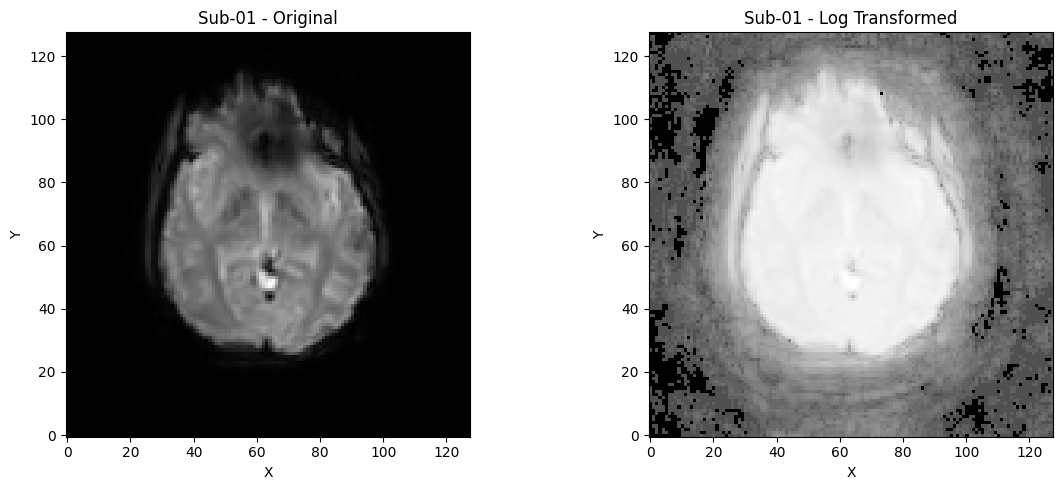

In [11]:
# ============================================
# Visual comparison
# ============================================

time_index = 0
z = sub01_data.shape[2] // 2

original_slice = sub01_data[:, :, z, time_index]
log_slice = log_data[:, :, z, time_index]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original
axes[0].imshow(
    original_slice.T,
    cmap="gray",
    origin="lower"
)

axes[0].set_title(
    "Sub-01 - Original"
)

axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")

# Log transformed
axes[1].imshow(
    log_slice.T,
    cmap="gray",
    origin="lower"
)

axes[1].set_title(
    "Sub-01 - Log Transformed"
)

axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")

plt.tight_layout()
plt.show()

In [12]:
# ============================================
# Contrast Stretching - Sub-01
# Applied after Log Transformation
# ============================================

# Create output array
contrast_data = np.zeros_like(
    log_data,
    dtype=np.float32
)

# Non-zero voxels
nonzero_mask = log_data > 0

# Get robust lower and upper intensity limits
lower_percentile = np.percentile(
    log_data[nonzero_mask],
    2
)

upper_percentile = np.percentile(
    log_data[nonzero_mask],
    98
)

print("Lower percentile (2%):", lower_percentile)
print("Upper percentile (98%):", upper_percentile)


# Contrast stretching
contrast_data[nonzero_mask] = np.clip(
    (
        log_data[nonzero_mask] - lower_percentile
    )
    /
    (
        upper_percentile - lower_percentile
    ),
    0,
    1
)


print("\nContrast stretching completed.")

print("\nLog-transformed data:")
print("Min :", log_data.min())
print("Max :", log_data.max())
print("Mean:", log_data.mean())
print("Std :", log_data.std())

print("\nAfter contrast stretching:")
print("Min :", contrast_data.min())
print("Max :", contrast_data.max())
print("Mean:", contrast_data.mean())
print("Std :", contrast_data.std())

Lower percentile (2%): 3.607789993286133
Upper percentile (98%): 10.889534950256348

Contrast stretching completed.

Log-transformed data:
Min : 0.0
Max : 11.79288
Mean: 5.72995
Std : 2.963848

After contrast stretching:
Min : 0.0
Max : 1.0
Mean: 0.33852175
Std : 0.33479184


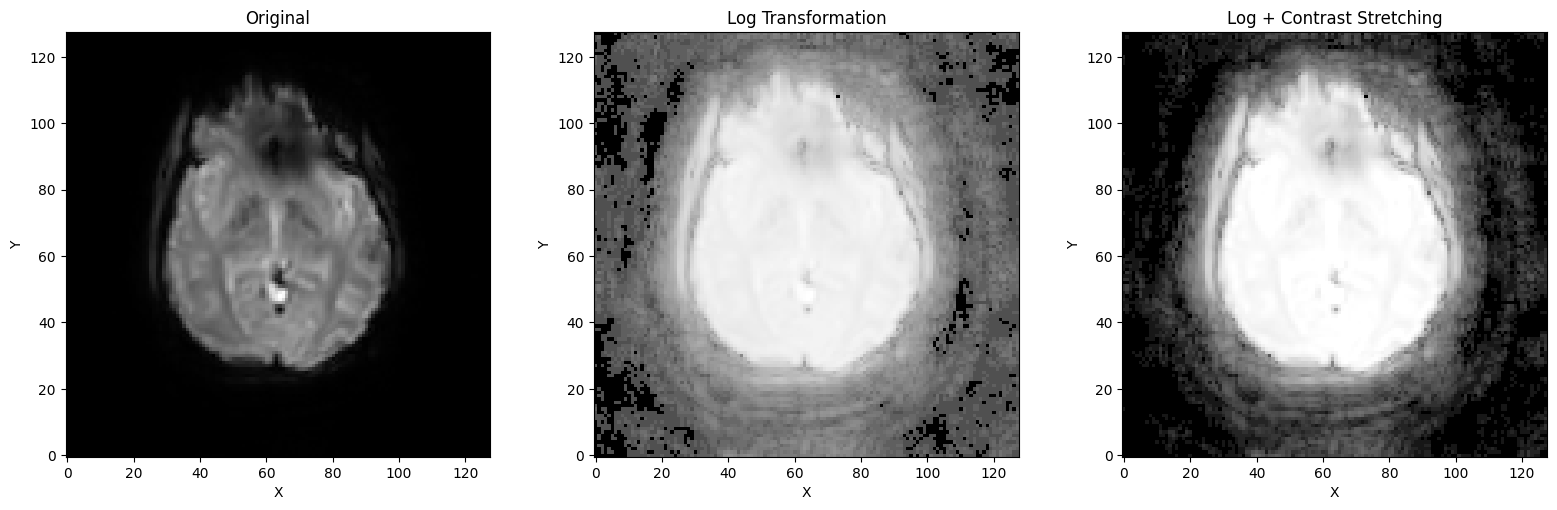

In [13]:
# ============================================
# Original vs Log vs Contrast Stretching
# ============================================

time_index = 0
z = sub01_data.shape[2] // 2

original_slice = sub01_data[:, :, z, time_index]
log_slice = log_data[:, :, z, time_index]
contrast_slice = contrast_data[:, :, z, time_index]


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)


# Original
axes[0].imshow(
    original_slice.T,
    cmap="gray",
    origin="lower"
)

axes[0].set_title("Original")


# Log
axes[1].imshow(
    log_slice.T,
    cmap="gray",
    origin="lower"
)

axes[1].set_title("Log Transformation")


# Contrast stretched
axes[2].imshow(
    contrast_slice.T,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "Log + Contrast Stretching"
)


for ax in axes:
    ax.set_xlabel("X")
    ax.set_ylabel("Y")


plt.tight_layout()
plt.show()

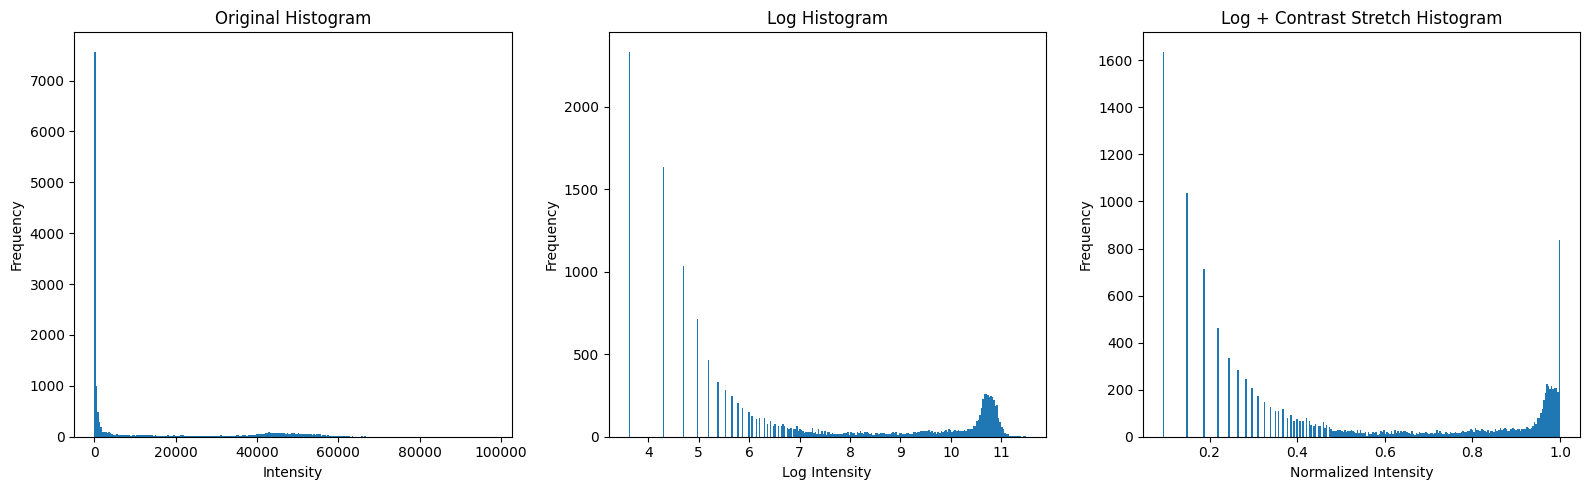

In [14]:
# ============================================
# Histogram comparison
# ============================================

original_nonzero = original_slice[
    original_slice > 0
]

log_nonzero = log_slice[
    log_slice > 0
]

contrast_nonzero = contrast_slice[
    contrast_slice > 0
]


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)


# Original
axes[0].hist(
    original_nonzero,
    bins=256
)

axes[0].set_title(
    "Original Histogram"
)

axes[0].set_xlabel("Intensity")
axes[0].set_ylabel("Frequency")


# Log
axes[1].hist(
    log_nonzero,
    bins=256
)

axes[1].set_title(
    "Log Histogram"
)

axes[1].set_xlabel("Log Intensity")
axes[1].set_ylabel("Frequency")


# Contrast
axes[2].hist(
    contrast_nonzero,
    bins=256
)

axes[2].set_title(
    "Log + Contrast Stretch Histogram"
)

axes[2].set_xlabel("Normalized Intensity")
axes[2].set_ylabel("Frequency")


plt.tight_layout()
plt.show()

In [15]:
# Check the effect of percentile clipping

nonzero_log = log_data[log_data > 0]

lower = np.percentile(nonzero_log, 2)
upper = np.percentile(nonzero_log, 98)

below_lower = np.sum(nonzero_log < lower)
above_upper = np.sum(nonzero_log > upper)
total_nonzero = len(nonzero_log)

print("Lower threshold:", lower)
print("Upper threshold:", upper)

print("\nValues below lower threshold:")
print(below_lower)

print("Values above upper threshold:")
print(above_upper)

print("Total non-zero values:")
print(total_nonzero)

print("\nPercentage clipped at lower end:")
print(100 * below_lower / total_nonzero, "%")

print("Percentage clipped at upper end:")
print(100 * above_upper / total_nonzero, "%")

Lower threshold: 3.607789993286133
Upper threshold: 10.889534950256348

Values below lower threshold:
0
Values above upper threshold:
2127242
Total non-zero values:
106697877

Percentage clipped at lower end:
0.0 %
Percentage clipped at upper end:
1.9937060228480459 %


In [16]:
import gc
import time
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd


# --------------------------------------------------
# PATHS
# --------------------------------------------------

CODE_DIR = Path.cwd()
DATA_DIR = CODE_DIR / "data"
OUTPUT_DIR = CODE_DIR / "processed_member1"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# FIND ALL 40 TASK-FE FILES
# --------------------------------------------------

fmri_files = sorted(
    DATA_DIR.glob("sub-*/func/*_task-fe_bold.nii.gz")
)

print("Total subjects found:", len(fmri_files))

for file in fmri_files:
    print(file)


# --------------------------------------------------
# PROCESS ALL 40 SUBJECTS
# --------------------------------------------------

processing_records = []

total_subjects = len(fmri_files)

for index, input_file in enumerate(fmri_files, start=1):

    subject = input_file.parent.parent.name
    start_time = time.time()

    print("\n" + "=" * 60)
    print(f"Processing {index}/{total_subjects}: {subject}")
    print("=" * 60)

    try:

        # --------------------------------------------------
        # LOAD NIFTI
        # --------------------------------------------------

        img = nib.load(input_file)

        data = img.get_fdata(dtype=np.float32)

        original_shape = data.shape

        print("Original shape:", original_shape)


        # --------------------------------------------------
        # 1. LOG TRANSFORMATION
        # --------------------------------------------------

        nonzero_mask = data > 0

        data[nonzero_mask] = np.log1p(data[nonzero_mask])


        # --------------------------------------------------
        # 2. CONTRAST STRETCHING
        #    Using 2nd and 98th percentiles
        # --------------------------------------------------

        nonzero_values = data[nonzero_mask]

        lower = np.percentile(nonzero_values, 2)
        upper = np.percentile(nonzero_values, 98)

        if upper <= lower:
            raise ValueError(
                f"Invalid percentile range: P2={lower}, P98={upper}"
            )

        data[nonzero_mask] = np.clip(
            (data[nonzero_mask] - lower) /
            (upper - lower),
            0,
            1
        )


        # --------------------------------------------------
        # SAVE PROCESSED DATA
        # --------------------------------------------------

        subject_output_dir = OUTPUT_DIR / subject
        subject_output_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        output_file = (
            subject_output_dir /
            f"{subject}_task-fe_bold_processed.nii.gz"
        )


        # --------------------------------------------------
        # PRESERVE NIFTI INFORMATION
        # --------------------------------------------------

        header = img.header.copy()

        header.set_data_dtype(np.float32)

        # Prevent unwanted intensity scaling
        header.set_slope_inter(1.0, 0.0)

        processed_img = nib.Nifti1Image(
            data,
            img.affine,
            header
        )

        nib.save(
            processed_img,
            output_file
        )


        # --------------------------------------------------
        # RECORD INFORMATION
        # --------------------------------------------------

        elapsed = time.time() - start_time

        processing_records.append({
            "subject": subject,
            "input_file": str(input_file),
            "output_file": str(output_file),
            "shape": str(original_shape),
            "P2": float(lower),
            "P98": float(upper),
            "output_min": float(data.min()),
            "output_max": float(data.max()),
            "output_mean": float(data.mean()),
            "output_std": float(data.std()),
            "status": "success",
            "time_seconds": round(elapsed, 2)
        })


        print("P2:", round(lower, 4))
        print("P98:", round(upper, 4))
        print("Output range: [0, 1]")
        print("Saved:", output_file)
        print(f"Time: {elapsed:.2f} seconds")


        # --------------------------------------------------
        # FREE MEMORY
        # --------------------------------------------------

        del data
        del processed_img
        del img
        del nonzero_mask
        del nonzero_values

        gc.collect()


    except Exception as e:

        processing_records.append({
            "subject": subject,
            "input_file": str(input_file),
            "output_file": "",
            "shape": "",
            "P2": np.nan,
            "P98": np.nan,
            "output_min": np.nan,
            "output_max": np.nan,
            "output_mean": np.nan,
            "output_std": np.nan,
            "status": f"failed: {e}",
            "time_seconds": np.nan
        })

        print("ERROR:", e)

        gc.collect()


# --------------------------------------------------
# CREATE PROCESSING MANIFEST
# --------------------------------------------------

processing_manifest = pd.DataFrame(processing_records)

manifest_file = (
    OUTPUT_DIR /
    "member1_processing_manifest.csv"
)

processing_manifest.to_csv(
    manifest_file,
    index=False
)


# --------------------------------------------------
# FINAL SUMMARY
# --------------------------------------------------

successful = (
    processing_manifest["status"] == "success"
).sum()

failed = (
    processing_manifest["status"] != "success"
).sum()

print("\n" + "=" * 60)
print("PROCESSING COMPLETED")
print("=" * 60)

print("Total subjects:", total_subjects)
print("Successful:", successful)
print("Failed:", failed)

print("\nManifest saved to:")
print(manifest_file)

display(processing_manifest)

Total subjects found: 40
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-01\func\sub-01_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-02\func\sub-02_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-03\func\sub-03_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-04\func\sub-04_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-05\func\sub-05_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-06\func\sub-06_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-07\func\sub-07_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-08\func\sub-08_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-09\func\sub-09_task-fe_bold.nii.gz
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-10\func\sub-10_task-fe_bold.nii.gz
D:\co

,subject,input_file,output_file,shape,P2,P98,output_min,output_max,output_mean,output_std,status,time_seconds
0,sub-01,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.607790,10.889535,0.0,1.0,0.338522,0.334792,success,52.65
1,sub-02,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.654612,10.963400,0.0,1.0,0.354719,0.350425,success,44.02
2,sub-03,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.765176,10.947392,0.0,1.0,0.323890,0.336272,success,50.05
3,sub-04,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.615118,10.940294,0.0,1.0,0.353372,0.356724,success,47.85
4,sub-05,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.616889,10.898217,0.0,1.0,0.346699,0.351216,success,58.48
5,sub-06,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.761746,10.994543,0.0,1.0,0.338187,0.340792,success,54.24
6,sub-07,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.612557,10.878241,0.0,1.0,0.373425,0.341129,success,55.69
7,sub-08,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.671329,10.956124,0.0,1.0,0.362878,0.346570,success,55.17
8,sub-09,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.652911,10.871614,0.0,1.0,0.317252,0.340405,success,49.41
9,sub-10,D:\coding\coding\projects\PROJECTS\Dip_capston...,D:\coding\coding\projects\PROJECTS\Dip_capston...,"(128, 128, 36, 200)",3.505656,10.911805,0.0,1.0,0.360792,0.331126,success,56.09


In [17]:
from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd

# --------------------------------------------------
# PATH
# --------------------------------------------------

OUTPUT_DIR = Path.cwd() / "processed_member1"

# --------------------------------------------------
# FIND ALL PROCESSED FILES
# --------------------------------------------------

processed_files = sorted(
    OUTPUT_DIR.glob("sub-*/ *_task-fe_bold_processed.nii.gz".replace(" ", ""))
)

print("Processed files found:", len(processed_files))

# --------------------------------------------------
# VERIFY EACH SUBJECT
# --------------------------------------------------

verification_records = []

for file in processed_files:

    subject = file.parent.name

    img = nib.load(file)
    data = img.get_fdata(dtype=np.float32)

    verification_records.append({
        "subject": subject,
        "shape": data.shape,
        "dtype": str(data.dtype),
        "min": float(np.min(data)),
        "max": float(np.max(data)),
        "mean": float(np.mean(data)),
        "std": float(np.std(data)),
        "NaN": bool(np.isnan(data).any()),
        "Inf": bool(np.isinf(data).any()),
        "voxel_x": float(img.header.get_zooms()[0]),
        "voxel_y": float(img.header.get_zooms()[1]),
        "voxel_z": float(img.header.get_zooms()[2]),
        "TR": float(img.header.get_zooms()[3])
    })

    del data

# --------------------------------------------------
# DISPLAY RESULTS
# --------------------------------------------------

verification_df = pd.DataFrame(verification_records)

display(verification_df)

Processed files found: 40


,subject,shape,dtype,min,max,mean,std,NaN,Inf,voxel_x,voxel_y,voxel_z,TR
0,sub-01,"(128, 128, 36, 200)",float32,0.0,1.0,0.338522,0.334792,False,False,1.796875,1.796875,4.0,3.000001
1,sub-02,"(128, 128, 36, 200)",float32,0.0,1.0,0.354719,0.350425,False,False,1.796875,1.796875,4.0,3.000001
2,sub-03,"(128, 128, 36, 200)",float32,0.0,1.0,0.323890,0.336272,False,False,1.789827,1.789827,4.0,3.000001
3,sub-04,"(128, 128, 36, 200)",float32,0.0,1.0,0.353372,0.356724,False,False,1.796875,1.796875,4.0,3.000001
4,sub-05,"(128, 128, 36, 200)",float32,0.0,1.0,0.346699,0.351216,False,False,1.796875,1.796875,4.0,3.000001
5,sub-06,"(128, 128, 36, 200)",float32,0.0,1.0,0.338187,0.340792,False,False,1.796875,1.796875,4.0,3.000001
6,sub-07,"(128, 128, 36, 200)",float32,0.0,1.0,0.373425,0.341129,False,False,1.796875,1.796875,4.0,3.000001
7,sub-08,"(128, 128, 36, 200)",float32,0.0,1.0,0.362878,0.346570,False,False,1.796875,1.796875,4.0,3.000001
8,sub-09,"(128, 128, 36, 200)",float32,0.0,1.0,0.317252,0.340405,False,False,1.796875,1.796875,4.0,3.000001
9,sub-10,"(128, 128, 36, 200)",float32,0.0,1.0,0.360792,0.331126,False,False,1.796875,1.796875,4.0,3.000001


In [18]:
import nibabel as nib
from pathlib import Path

RAW_DIR = Path.cwd() / "data"
PROCESSED_DIR = Path.cwd() / "processed_member1"

results = []

for subject in sorted(
    [f"sub-{i:02d}" for i in range(1, 41)]
):
    raw_file = RAW_DIR / subject / "func" / f"{subject}_task-fe_bold.nii.gz"
    processed_file = (
        PROCESSED_DIR / subject /
        f"{subject}_task-fe_bold_processed.nii.gz"
    )

    raw_img = nib.load(raw_file)
    processed_img = nib.load(processed_file)

    results.append({
        "subject": subject,
        "raw_orientation": "".join(nib.aff2axcodes(raw_img.affine)),
        "processed_orientation": "".join(nib.aff2axcodes(processed_img.affine)),
        "affine_same": np.allclose(
            raw_img.affine,
            processed_img.affine
        )
    })

orientation_df = pd.DataFrame(results)

display(orientation_df)

print("All orientations preserved:",
      (orientation_df["raw_orientation"] ==
       orientation_df["processed_orientation"]).all())

print("All affines preserved:",
      orientation_df["affine_same"].all())

,subject,raw_orientation,processed_orientation,affine_same
0,sub-01,LAS,LAS,True
1,sub-02,LAS,LAS,True
2,sub-03,LAS,LAS,True
3,sub-04,LAS,LAS,True
4,sub-05,LAS,LAS,True
5,sub-06,LAS,LAS,True
6,sub-07,LAS,LAS,True
7,sub-08,LAS,LAS,True
8,sub-09,LAS,LAS,True
9,sub-10,LAS,LAS,True


All orientations preserved: True
All affines preserved: True


Raw shape: (128, 128, 36, 200)
Processed shape: (128, 128, 36, 200)
Raw range: 0.0 to 132305.97
Processed range: 0.0 to 1.0


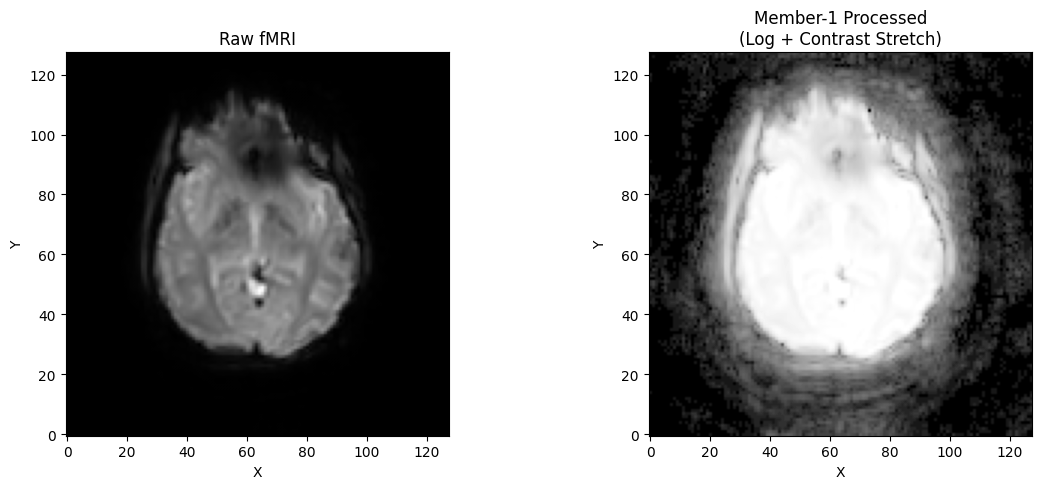

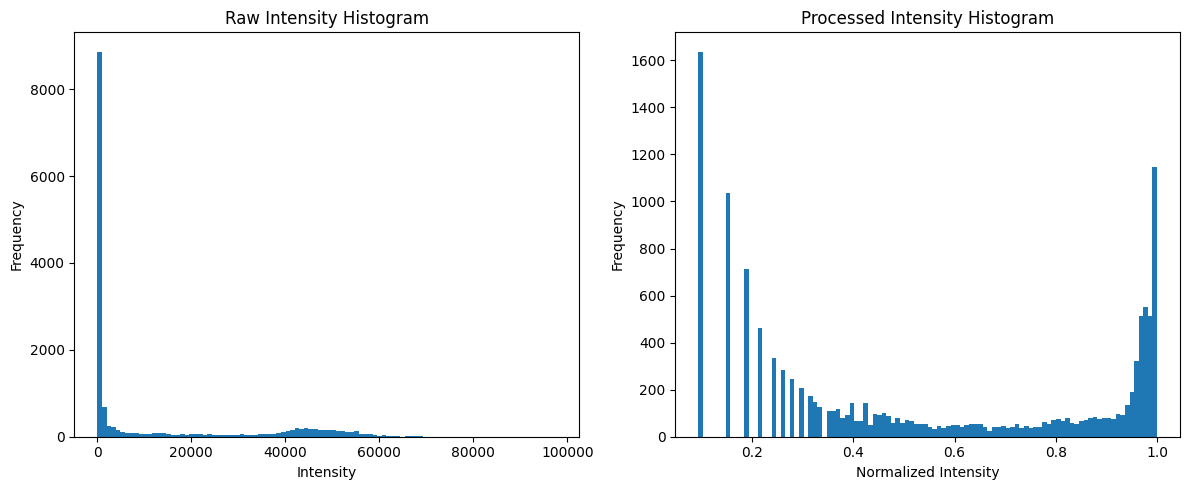

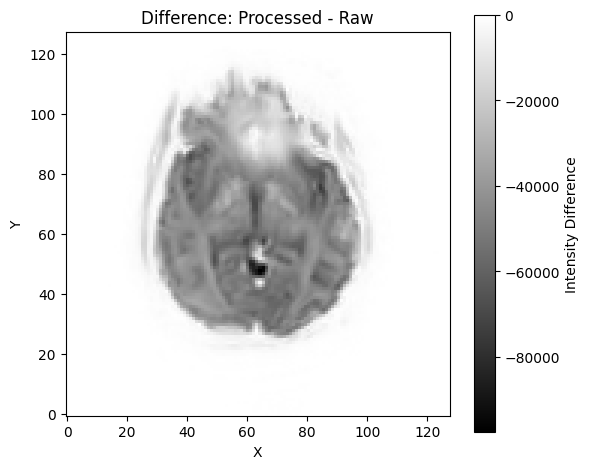


--- Slice Comparison ---
Raw:
  Min    : 0.0
  Max    : 97641.586
  Mean   : 11951.412
  Std    : 19374.418

Processed:
  Min    : 0.0
  Max    : 1.0
  Mean   : 0.42316666
  Std    : 0.37670478

Difference:
  Mean absolute difference: 11950.988
  Maximum absolute difference: 97640.586


In [19]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# Paths
# --------------------------------------------------
CODE_DIR = Path.cwd()
DATA_DIR = CODE_DIR / "data"
PROCESSED_DIR = CODE_DIR / "processed_member1"

raw_file = DATA_DIR / "sub-01" / "func" / "sub-01_task-fe_bold.nii.gz"
processed_file = (
    PROCESSED_DIR
    / "sub-01"
    / "sub-01_task-fe_bold_processed.nii.gz"
)

# --------------------------------------------------
# Load images
# --------------------------------------------------
raw_img = nib.load(raw_file)
processed_img = nib.load(processed_file)

raw_data = raw_img.get_fdata(dtype=np.float32)
processed_data = processed_img.get_fdata(dtype=np.float32)

print("Raw shape:", raw_data.shape)
print("Processed shape:", processed_data.shape)
print("Raw range:", raw_data.min(), "to", raw_data.max())
print("Processed range:", processed_data.min(), "to", processed_data.max())

# --------------------------------------------------
# Select same time point and middle axial slice
# --------------------------------------------------
t = 0
z = raw_data.shape[2] // 2

raw_slice = raw_data[:, :, z, t]
processed_slice = processed_data[:, :, z, t]

# Difference
difference = processed_slice - raw_slice

# --------------------------------------------------
# 1. RAW vs PROCESSED
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(raw_slice.T, cmap="gray", origin="lower")
axes[0].set_title("Raw fMRI")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")

axes[1].imshow(processed_slice.T, cmap="gray", origin="lower",
               vmin=0, vmax=1)
axes[1].set_title("Member-1 Processed\n(Log + Contrast Stretch)")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. HISTOGRAM COMPARISON
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw histogram - use nonzero values
raw_nonzero = raw_slice[raw_slice > 0]

axes[0].hist(raw_nonzero.ravel(), bins=100)
axes[0].set_title("Raw Intensity Histogram")
axes[0].set_xlabel("Intensity")
axes[0].set_ylabel("Frequency")

# Processed histogram
processed_nonzero = processed_slice[processed_slice > 0]

axes[1].hist(processed_nonzero.ravel(), bins=100)
axes[1].set_title("Processed Intensity Histogram")
axes[1].set_xlabel("Normalized Intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. DIFFERENCE IMAGE
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(difference.T, cmap="gray", origin="lower")

ax.set_title("Difference: Processed - Raw")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.colorbar(im, ax=ax, label="Intensity Difference")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Basic numerical comparison
# --------------------------------------------------
print("\n--- Slice Comparison ---")
print("Raw:")
print("  Min    :", raw_slice.min())
print("  Max    :", raw_slice.max())
print("  Mean   :", raw_slice.mean())
print("  Std    :", raw_slice.std())

print("\nProcessed:")
print("  Min    :", processed_slice.min())
print("  Max    :", processed_slice.max())
print("  Mean   :", processed_slice.mean())
print("  Std    :", processed_slice.std())

print("\nDifference:")
print("  Mean absolute difference:",
      np.mean(np.abs(difference)))
print("  Maximum absolute difference:",
      np.max(np.abs(difference)))